In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as si

## Implement PCHIP

my_pchip function compute the node derivative for PCHIP interpolation. This function follows the formula from the Project 2 report.

In [18]:
def my_pchip(x,y):
    # 1. get the n
    n = len(x) - 1
    delta = np.zeros(n)
    d = np.zeros(n+1)
    # 2. calculate the secant slope for each interval
    for i in range(n):
        delta[i] = (y[i+1]-y[i])/(x[i+1]-x[i])

    # 3. calculate the interior derivatives
    for i in range(1,n-1):
        if(delta[i-1]*delta[i] <= 0):
            d[i] = 0
        else:
            d[i] = 2. / (1./delta[i-1] + 1./delta[i])
            
    # 4. Compute boundary derivatives(d[0] and d[n]) using non centered three-point formulas
    if n >= 2:
        h0 = x[1] - x[0]
        h1 = x[2] - x[1]
        d0_cand = ((2. * h0 + h1) * delta[0] - h0 * delta[1]) / (h0 + h1)
        if (d0_cand * delta[0] <= 0):
            d[0] = 0.0
        else:
            d[0] = d0_cand

        hn_1 = x[n] - x[n - 1]
        hn_2 = x[n - 1] - x[n - 2]
        dn_cand = ((2. * hn_1 + hn_2) * delta[n - 1] - hn_1 * delta[n - 2]) / (hn_1 + hn_2)
        if (dn_cand * delta[n - 1] <= 0):
            d[n] = 0.0
        else:
            d[n] = dn_cand
    elif n == 1:
        d[0] = d[1] = delta[0]

    return d


## Test Case 1: Monotone Increasing

x = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10.]

y = [0, 0.1, 0.3, 1.8, 2.0, 2.9, 3.0, 4.5, 4.6, 4.7, 4.7]

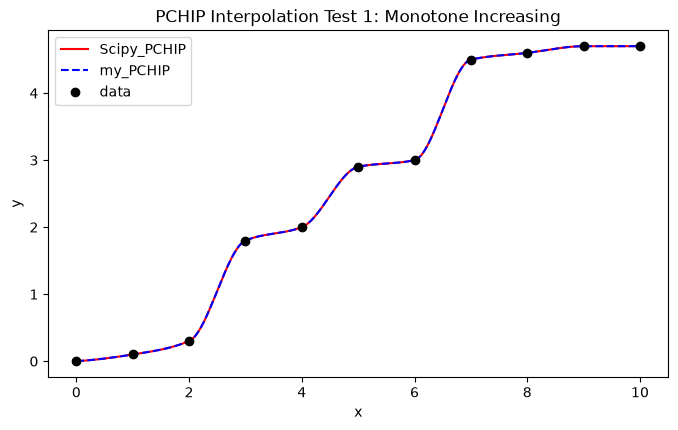

In [32]:
x = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10.])
y = np.array([0, 0.1, 0.3, 1.8, 2.0, 2.9, 3.0, 4.5, 4.6, 4.7, 4.7])

pchip_scipy = si.PchipInterpolator(x, y) #PCHIP Interpolation from Scipy Library
pchip_my_d = si.CubicHermiteSpline(x,y,my_pchip(x,y)) # created PCHIP Interpolation

xnew = np.linspace(0, 10, 1001)
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(xnew,pchip_scipy(xnew),"red", label="Scipy_PCHIP")
ax.plot(xnew,pchip_my_d(xnew),"b--",label="my_PCHIP")

ax.plot(x, y, "ko", label="data")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend()
ax.set_title("PCHIP Interpolation Test 1: Monotone Increasing")
fig.savefig("PCHIP_test_1.png", dpi=300)
plt.show()


## Test Case 2: Monotone Decreasing
x = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10.]

y = [8, 7.7, 7.7, 7.7, 6.9, 5.0, 4.5, 4.0, 2.0, 1.9, 1.8]

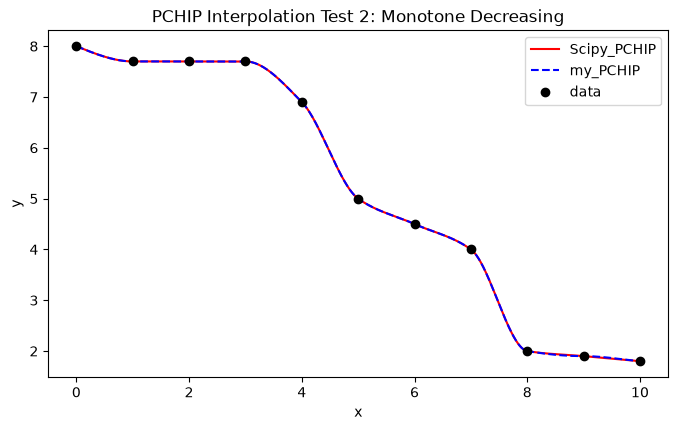

In [33]:
x = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10.])
y = np.array([8, 7.7, 7.7, 7.7, 6.9, 5.0, 4.5, 4.0, 2.0, 1.9, 1.8])

pchip_scipy = si.PchipInterpolator(x, y) #PCHIP Interpolation from Scipy Library
pchip_my_d = si.CubicHermiteSpline(x,y,my_pchip(x,y)) # created PCHIP Interpolation

xnew = np.linspace(0, 10, 1001)
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(xnew,pchip_scipy(xnew),"red", label="Scipy_PCHIP")
ax.plot(xnew,pchip_my_d(xnew),"b--",label="my_PCHIP")

ax.plot(x, y, "ko", label="data")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend()
ax.set_title("PCHIP Interpolation Test 2: Monotone Decreasing")
fig.savefig("PCHIP_test_2.png", dpi=300)
plt.show()
